# Dual-frequency shared-eta MAP inversion

This notebook tests a full-time-series dual-frequency inverse problem using one L1/L5 realization from Kaggle dataset version 6. The latent variable is a Hermitian Gaussian Fourier-domain vector `eta`; each frequency applies its own two-component power-law shaping operator, linear detrending, screen exponential, and Fresnel forward propagation.

The implemented objective is:

```text
minimize over eta:
    ||A_L1 exp(i F_L1 eta) - y_L1||^2
  + ||A_L5 exp(i F_L5 eta) - y_L5||^2
  + lambda ||eta||^2
```

The full optimization is intentionally gated by `run_optimization`. The first cells are safe to run and compute model/initialization diagnostics before launching the expensive nonlinear least-squares solve.


In [1]:
from pathlib import Path
import json
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from loguru import logger
from scipy.fft import fft, ifft
from scipy.optimize import least_squares
from scipy.sparse.linalg import LinearOperator

plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 9,
        "legend.title_fontsize": 10,
        "lines.linewidth": 1.6,
        "lines.markersize": 5,
        "figure.dpi": 120,
    }
)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_root / "outputs" / "dual_frequency_shared_eta_inversion"
output_dir.mkdir(parents=True, exist_ok=True)

DATASET_HANDLE = "rodrigodlf/backpropagation/versions/6"
example_valid_position = 0

# Work on a cropped segment first. Full-series inversion is much more expensive
# and can exhaust WSL memory if any dense Jacobian path is triggered.
N_WORK = 4096
N_WORK_START = 0

# Set run_optimization=True after the cropped setup cells pass.
run_optimization = True
init_mode = "best_observed_phase"  # "best_observed_phase", "zero", "backprop_l1_phase", "backprop_l5_phase", "dual_backprop_phase", or "true_l1_phase_sanity"
regularization_lambda = 1e-2
use_staged_continuation = True
continuation_stages = [
    # Start with a very smooth, low-dimensional branch estimate. Later stages are
    # softly anchored to the previous stage, which prevents the high-frequency
    # modes from absorbing local 2*pi branch mistakes.
    {"name": "low_modes_branch_seed", "mode_fraction": 0.08, "lambda_eta": 3e-2, "lambda_grad": 3e-1, "lambda_curv": 3e0, "lambda_ref": 0.0, "max_nfev": 60},
    {"name": "low_mid_modes_branch_locked", "mode_fraction": 0.18, "lambda_eta": 2e-2, "lambda_grad": 2e-1, "lambda_curv": 1e0, "lambda_ref": 5e-1, "max_nfev": 60},
    {"name": "mid_modes_branch_locked", "mode_fraction": 0.35, "lambda_eta": 1.5e-2, "lambda_grad": 1e-1, "lambda_curv": 3e-1, "lambda_ref": 2e-1, "max_nfev": 60},
    {"name": "wide_modes_branch_locked", "mode_fraction": 0.65, "lambda_eta": 1e-2, "lambda_grad": 6e-2, "lambda_curv": 1e-1, "lambda_ref": 8e-2, "max_nfev": 60},
    {"name": "all_modes_branch_polish", "mode_fraction": 1.00, "lambda_eta": 1e-2, "lambda_grad": 3e-2, "lambda_curv": 3e-2, "lambda_ref": 3e-2, "max_nfev": 80},
]
max_nfev = 80
least_squares_method = "trf"
tr_solver = "lsmr"
loss = "linear"
log_every_residual_calls = 5

plot_start = 400
plot_len = 1200
phase_edge_guard_samples = 256

logger.remove()
logger.add(lambda msg: print(msg, end=""), level="INFO")
logger.info("Configured dual-frequency shared-eta inversion notebook")


/home/rodrigo/github/real-time-bp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-05-18 12:48:39.319 | INFO     | __main__:<module>:68 - Configured dual-frequency shared-eta inversion notebook


In [2]:
logger.info("Loading Kaggle dataset {}", DATASET_HANDLE)
path = Path(kagglehub.dataset_download(DATASET_HANDLE))
tracked_path = path / "tracked"

X_raw = np.load(tracked_path / "X_main.npy", mmap_mode="r")
y_df = pd.read_csv(tracked_path / "y_main.csv")
meta = json.loads((tracked_path / "meta_main.json").read_text())
channel_labels = meta["channel_labels"]
dt = float(meta["t_samp_sec"])
Fs = 1.0 / dt

required_channels = [
    "true_intensity_L1",
    "true_intensity_L5",
    "postprop_phase_L1",
    "postprop_phase_L5",
    "refractive_phase_L1",
    "refractive_phase_L5",
]
missing_channels = [name for name in required_channels if name not in channel_labels]
if missing_channels:
    raise ValueError(f"Dataset is missing required channels: {missing_channels}")

required_columns = [
    "U_L1",
    "U_L5",
    "mu0_L1",
    "mu0_L5",
    "p1",
    "p2",
    "rhof_veff_ratio_L1",
    "rhof_veff_ratio_L5",
    "loss_of_lock_L1",
    "loss_of_lock_L5",
]
missing_columns = [name for name in required_columns if name not in y_df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

lock_l1 = y_df["loss_of_lock_L1"].astype(str).str.lower().isin(["true", "1", "yes", "y"]).to_numpy()
lock_l5 = y_df["loss_of_lock_L5"].astype(str).str.lower().isin(["true", "1", "yes", "y"]).to_numpy()
valid_realizations = np.flatnonzero(~lock_l1 & ~lock_l5)
if len(valid_realizations) == 0:
    raise ValueError("No dual-frequency lock-valid realization is available.")

example_realization_idx = int(valid_realizations[example_valid_position])
row = y_df.iloc[example_realization_idx]
N_TOTAL = int(X_raw.shape[1])
work_start = int(N_WORK_START)
if work_start < 0 or work_start >= N_TOTAL:
    raise ValueError(f"N_WORK_START must be in [0, {N_TOTAL}); got {work_start}")
work_stop = N_TOTAL if N_WORK is None else min(work_start + int(N_WORK), N_TOTAL)
if work_stop <= work_start:
    raise ValueError(f"Empty work segment: start={work_start}, stop={work_stop}")
work_slice = slice(work_start, work_stop)
N = int(work_stop - work_start)

idx = {name: channel_labels.index(name) for name in required_channels}
true_intensity_l1 = np.maximum(np.asarray(X_raw[example_realization_idx, work_slice, idx["true_intensity_L1"]], dtype=np.float64), 0.0)
true_intensity_l5 = np.maximum(np.asarray(X_raw[example_realization_idx, work_slice, idx["true_intensity_L5"]], dtype=np.float64), 0.0)
postprop_phase_l1 = np.asarray(X_raw[example_realization_idx, work_slice, idx["postprop_phase_L1"]], dtype=np.float64)
postprop_phase_l5 = np.asarray(X_raw[example_realization_idx, work_slice, idx["postprop_phase_L5"]], dtype=np.float64)
true_phi_l1 = np.asarray(X_raw[example_realization_idx, work_slice, idx["refractive_phase_L1"]], dtype=np.float64)
true_phi_l5 = np.asarray(X_raw[example_realization_idx, work_slice, idx["refractive_phase_L5"]], dtype=np.float64)

# True post-propagated fields. These are used as y_L1 and y_L5.
y_l1 = np.sqrt(true_intensity_l1) * np.exp(1j * postprop_phase_l1)
y_l5 = np.sqrt(true_intensity_l5) * np.exp(1j * postprop_phase_l5)
true_screen_l1 = np.exp(1j * true_phi_l1)
true_screen_l5 = np.exp(1j * true_phi_l5)

params = {
    "example_realization_idx": example_realization_idx,
    "N": N,
    "N_TOTAL": N_TOTAL,
    "N_WORK": N_WORK,
    "N_WORK_START": work_start,
    "N_WORK_STOP": work_stop,
    "dt_s": dt,
    "Fs_hz": Fs,
    "U_L1": float(row["U_L1"]),
    "U_L5": float(row["U_L5"]),
    "mu0_L1": float(row["mu0_L1"]),
    "mu0_L5": float(row["mu0_L5"]),
    "p1": float(row["p1"]),
    "p2": float(row["p2"]),
    "rho_over_v_L1_s": float(row["rhof_veff_ratio_L1"]),
    "rho_over_v_L5_s": float(row["rhof_veff_ratio_L5"]),
    "init_mode": init_mode,
    "regularization_lambda": regularization_lambda,
    "use_staged_continuation": use_staged_continuation,
    "continuation_stages": json.dumps(continuation_stages),
    "run_optimization": run_optimization,
    "phase_edge_guard_samples": phase_edge_guard_samples,
    "output_dir": str(output_dir),
}
pd.DataFrame([params]).to_csv(output_dir / "shared_eta_initialization.csv", index=False)
logger.info("Loaded realization {} with work segment [{}:{}) -> N={} samples", example_realization_idx, work_start, work_stop, N)
params


2026-05-18 12:48:39.328 | INFO     | __main__:<module>:1 - Loading Kaggle dataset rodrigodlf/backpropagation/versions/6
2026-05-18 12:48:39.450 | INFO     | __main__:<module>:98 - Loaded realization 0 with work segment [0:4096) -> N=4096 samples


{'example_realization_idx': 0,
 'N': 4096,
 'N_TOTAL': 15000,
 'N_WORK': 4096,
 'N_WORK_START': 0,
 'N_WORK_STOP': 4096,
 'dt_s': 0.02,
 'Fs_hz': 50.0,
 'U_L1': 2.962747837118292,
 'U_L5': 6.2364914360064105,
 'mu0_L1': 9.295357244937168,
 'mu0_L5': 10.756662086068744,
 'p1': 2.097591843427206,
 'p2': 3.0723349722676287,
 'rho_over_v_L1_s': 1.4130542610142245,
 'rho_over_v_L5_s': 1.6351977438294074,
 'init_mode': 'best_observed_phase',
 'regularization_lambda': 0.01,
 'use_staged_continuation': True,
 'continuation_stages': '[{"name": "low_modes_branch_seed", "mode_fraction": 0.08, "lambda_eta": 0.03, "lambda_grad": 0.3, "lambda_curv": 3.0, "lambda_ref": 0.0, "max_nfev": 60}, {"name": "low_mid_modes_branch_locked", "mode_fraction": 0.18, "lambda_eta": 0.02, "lambda_grad": 0.2, "lambda_curv": 1.0, "lambda_ref": 0.5, "max_nfev": 60}, {"name": "mid_modes_branch_locked", "mode_fraction": 0.35, "lambda_eta": 0.015, "lambda_grad": 0.1, "lambda_curv": 0.3, "lambda_ref": 0.2, "max_nfev": 60}, 

In [3]:
def two_component_phase_psd(mu, U, mu0, p1, p2):
    """Two-component normalized phase SDF P(mu), matching the local MATLAB helper."""
    mu = np.asarray(mu, dtype=np.float64)
    abs_mu = np.abs(mu)
    P = np.zeros_like(abs_mu)
    nonzero = abs_mu > 0
    Cpp = U if mu0 >= 1.0 else U / (mu0 ** (p2 - p1))
    below = nonzero & (abs_mu <= mu0)
    above = nonzero & (abs_mu > mu0)
    P[below] = Cpp * abs_mu[below] ** (-p1)
    P[above] = Cpp * (mu0 ** (p2 - p1)) * abs_mu[above] ** (-p2)
    return P


def linex_detrend_adjoint(g):
    """Adjoint of y = x - line(x[0], x[-1])."""
    n = len(g)
    t = np.linspace(0.0, 1.0, n)
    out = np.asarray(g, dtype=np.float64).copy()
    out[0] -= np.sum(g * (1.0 - t))
    out[-1] -= np.sum(g * t)
    return out


class HermitianEtaParameterization:
    """Map N real degrees of freedom to Hermitian FFT-bin eta."""

    def __init__(self, n):
        if n % 2 != 0:
            raise ValueError("This implementation currently expects an even sample count.")
        self.n = int(n)
        self.n_pos = self.n // 2 - 1
        self.size = self.n

    def to_eta_fft(self, x):
        x = np.asarray(x, dtype=np.float64).reshape(-1)
        if len(x) != self.size:
            raise ValueError(f"Expected x size {self.size}, got {len(x)}")
        eta = np.zeros(self.n, dtype=np.complex128)
        eta[0] = x[0]
        eta[self.n // 2] = x[1]
        re = x[2 : 2 + self.n_pos]
        im = x[2 + self.n_pos : 2 + 2 * self.n_pos]
        z = re + 1j * im
        eta[1 : self.n // 2] = z
        eta[self.n // 2 + 1 :] = np.conj(z[::-1])
        return eta

    def from_eta_fft(self, eta):
        eta = np.asarray(eta, dtype=np.complex128).reshape(-1)
        x = np.zeros(self.size, dtype=np.float64)
        x[0] = np.real(eta[0])
        x[1] = np.real(eta[self.n // 2])
        z = eta[1 : self.n // 2]
        x[2 : 2 + self.n_pos] = np.real(z)
        x[2 + self.n_pos : 2 + 2 * self.n_pos] = np.imag(z)
        return x

    def adjoint_from_eta_gradient(self, g_eta):
        g_eta = np.asarray(g_eta, dtype=np.complex128).reshape(-1)
        out = np.zeros(self.size, dtype=np.float64)
        out[0] = np.real(g_eta[0])
        out[1] = np.real(g_eta[self.n // 2])
        g_pos = g_eta[1 : self.n // 2]
        g_neg = g_eta[self.n - 1 : self.n // 2 : -1]
        out[2 : 2 + self.n_pos] = np.real(g_pos + g_neg)
        out[2 + self.n_pos : 2 + 2 * self.n_pos] = np.imag(g_pos) - np.imag(g_neg)
        return out


class PhaseShapingOperator:
    """Real-linear operator x -> detrended phase for one frequency."""

    def __init__(self, n, dt, rho_over_v, U, mu0, p1, p2, eta_param):
        self.n = int(n)
        self.dt = float(dt)
        self.rho_over_v = float(rho_over_v)
        self.U = float(U)
        self.mu0 = float(mu0)
        self.p1 = float(p1)
        self.p2 = float(p2)
        self.eta_param = eta_param
        self.frequency_hz_centered = np.fft.fftshift(np.fft.fftfreq(self.n, d=self.dt))
        self.mu_centered = 2.0 * np.pi * self.frequency_hz_centered * self.rho_over_v
        self.delta_mu = float(self.mu_centered[1] - self.mu_centered[0])
        self.P_mu_centered = two_component_phase_psd(self.mu_centered, self.U, self.mu0, self.p1, self.p2)
        self.root_centered = np.sqrt(self.P_mu_centered * abs(self.delta_mu) / (2.0 * np.pi))
        self.root_fft = np.fft.ifftshift(self.root_centered)
        self.t = np.linspace(0.0, 1.0, self.n)

    def detrend(self, raw_phase):
        line = (1.0 - self.t) * raw_phase[0] + self.t * raw_phase[-1]
        return raw_phase - line

    def matvec(self, x):
        eta_fft = self.eta_param.to_eta_fft(x)
        phase_spectrum_fft = self.root_fft * eta_fft
        raw_phase = np.real(np.fft.fftshift(ifft(phase_spectrum_fft))) * self.n
        return self.detrend(raw_phase)

    def rmatvec(self, g_phase):
        h = linex_detrend_adjoint(np.asarray(g_phase, dtype=np.float64))
        h_unshifted = np.fft.ifftshift(h)
        g_spectrum = self.root_fft * fft(h_unshifted)
        return self.eta_param.adjoint_from_eta_gradient(g_spectrum)

    def approximate_inverse_from_phase(self, phase, eps=1e-12):
        """Build a sanity-check eta initialization from a target phase sequence."""
        phase_unshifted = np.fft.ifftshift(np.asarray(phase, dtype=np.float64))
        spectrum_fft = fft(phase_unshifted) / self.n
        eta_fft = np.zeros(self.n, dtype=np.complex128)
        valid = self.root_fft > eps
        eta_fft[valid] = spectrum_fft[valid] / self.root_fft[valid]
        # Project back to Hermitian space.
        x = self.eta_param.from_eta_fft(eta_fft)
        return x


def propagation_kernel(n, dt, rho_over_v, direction="forward"):
    f = np.fft.fftfreq(n, d=dt)
    sign = -1.0 if direction == "forward" else 1.0
    return np.exp(0.5j * sign * (2.0 * np.pi * f * rho_over_v) ** 2)


def propagate_field(field, H):
    return ifft(fft(field) * H)


def compute_complex_field_metrics(reference, estimate, label):
    idx = np.isfinite(reference) & np.isfinite(estimate)
    if not np.any(idx):
        return {"label": label, "num_valid_samples": 0, "field_rel_error": np.nan, "amp_rmse": np.nan, "phase_rmse_rad": np.nan}
    phase_error = np.angle(estimate[idx] * np.conj(reference[idx]))
    return {
        "label": label,
        "num_valid_samples": int(np.sum(idx)),
        "field_rel_error": float(np.linalg.norm(estimate[idx] - reference[idx]) / np.linalg.norm(reference[idx])),
        "amp_rmse": float(np.sqrt(np.mean((np.abs(estimate[idx]) - np.abs(reference[idx])) ** 2))),
        "phase_rmse_rad": float(np.sqrt(np.mean(phase_error ** 2))),
    }


def unwrap_align(phase, reference):
    phase = np.unwrap(np.asarray(phase, dtype=np.float64))
    reference = np.unwrap(np.asarray(reference, dtype=np.float64))
    return phase - np.median(phase - reference)


def first_difference(x):
    return np.diff(np.asarray(x, dtype=np.float64))


def first_difference_adjoint(v, n):
    v = np.asarray(v, dtype=np.float64).reshape(-1)
    out = np.zeros(int(n), dtype=np.float64)
    out[:-1] -= v
    out[1:] += v
    return out


def second_difference(x):
    x = np.asarray(x, dtype=np.float64)
    return x[:-2] - 2.0 * x[1:-1] + x[2:]


def second_difference_adjoint(v, n):
    v = np.asarray(v, dtype=np.float64).reshape(-1)
    out = np.zeros(int(n), dtype=np.float64)
    out[:-2] += v
    out[1:-1] -= 2.0 * v
    out[2:] += v
    return out


def active_eta_indices(eta_param, mode_fraction):
    """Return real-parameter indices for the lowest positive Fourier bins."""
    frac = float(mode_fraction)
    if not (0 < frac <= 1):
        raise ValueError(f"mode_fraction must be in (0, 1]; got {mode_fraction}")
    n_pos = eta_param.n_pos
    k_keep = int(np.ceil(n_pos * frac))
    k_keep = max(1, min(n_pos, k_keep))
    indices = [0]  # DC. This is usually ineffective because P(0)=0, but harmless.
    if frac >= 1.0:
        indices.append(1)  # Nyquist only in the full-mode stage.
    re_start = 2
    im_start = 2 + n_pos
    indices.extend(range(re_start, re_start + k_keep))
    indices.extend(range(im_start, im_start + k_keep))
    return np.asarray(sorted(set(indices)), dtype=int)

logger.info("Defined spectral shaping, Hermitian eta, propagation, and metric helpers")


2026-05-18 12:48:39.467 | INFO     | __main__:<module>:192 - Defined spectral shaping, Hermitian eta, propagation, and metric helpers


In [4]:
eta_param = HermitianEtaParameterization(N)
F_l1 = PhaseShapingOperator(
    n=N,
    dt=dt,
    rho_over_v=float(row["rhof_veff_ratio_L1"]),
    U=float(row["U_L1"]),
    mu0=float(row["mu0_L1"]),
    p1=float(row["p1"]),
    p2=float(row["p2"]),
    eta_param=eta_param,
)
F_l5 = PhaseShapingOperator(
    n=N,
    dt=dt,
    rho_over_v=float(row["rhof_veff_ratio_L5"]),
    U=float(row["U_L5"]),
    mu0=float(row["mu0_L5"]),
    p1=float(row["p1"]),
    p2=float(row["p2"]),
    eta_param=eta_param,
)
H_l1 = propagation_kernel(N, dt, float(row["rhof_veff_ratio_L1"]), direction="forward")
H_l5 = propagation_kernel(N, dt, float(row["rhof_veff_ratio_L5"]), direction="forward")
H_l1_adj = np.conj(H_l1)
H_l5_adj = np.conj(H_l5)

data_weight = 1.0 / np.sqrt(N)
prior_weight = np.sqrt(regularization_lambda / N)

# Full-batch inverse propagation gives a branch-aware initialization from the
# observed complex post-propagated fields. This is the best initialization for
# this notebook's offline full-window test and does not use the true screen.
bp_screen_l1 = propagate_field(y_l1, H_l1_adj)
bp_screen_l5 = propagate_field(y_l5, H_l5_adj)
bp_phi_l1 = F_l1.detrend(np.unwrap(np.angle(bp_screen_l1)))
bp_phi_l5 = F_l5.detrend(np.unwrap(np.angle(bp_screen_l5)))
x_bp_l1 = F_l1.approximate_inverse_from_phase(bp_phi_l1)
x_bp_l5 = F_l5.approximate_inverse_from_phase(bp_phi_l5)
x_bp_dual = 0.5 * (x_bp_l1 + x_bp_l5)

x_init_candidates = {
    "zero": np.zeros(eta_param.size, dtype=np.float64),
    "backprop_l1_phase": x_bp_l1,
    "backprop_l5_phase": x_bp_l5,
    "dual_backprop_phase": x_bp_dual,
    "true_l1_phase_sanity": F_l1.approximate_inverse_from_phase(true_phi_l1),
}


def initial_candidate_cost(x):
    phi_l1 = F_l1.matvec(x)
    phi_l5 = F_l5.matvec(x)
    yhat_l1 = propagate_field(np.exp(1j * phi_l1), H_l1)
    yhat_l5 = propagate_field(np.exp(1j * phi_l5), H_l5)
    e_l1 = yhat_l1 - y_l1
    e_l5 = yhat_l5 - y_l5
    data_cost_l1 = 0.5 * float(data_weight ** 2 * np.vdot(e_l1, e_l1).real)
    data_cost_l5 = 0.5 * float(data_weight ** 2 * np.vdot(e_l5, e_l5).real)
    prior_cost = 0.5 * float(prior_weight ** 2 * np.dot(x, x))
    return data_cost_l1 + data_cost_l5 + prior_cost


observed_init_names = ["zero", "backprop_l1_phase", "backprop_l5_phase", "dual_backprop_phase"]
observed_init_costs = {name: initial_candidate_cost(x_init_candidates[name]) for name in observed_init_names}
if init_mode == "best_observed_phase":
    selected_init_mode = min(observed_init_costs, key=observed_init_costs.get)
else:
    selected_init_mode = init_mode
if selected_init_mode not in x_init_candidates:
    raise ValueError(f"Unknown init_mode: {init_mode}; choose one of {['best_observed_phase'] + list(x_init_candidates)}")
x0 = x_init_candidates[selected_init_mode]

logger.info("Built F_L1, F_L5 and propagation kernels")
logger.info("Eta degrees of freedom: {} real parameters", eta_param.size)
for candidate_name, candidate_x in x_init_candidates.items():
    logger.info("Initialization candidate {}: ||x||={:.3e}", candidate_name, np.linalg.norm(candidate_x))
logger.info("Selected initialization mode: {} -> {}", init_mode, selected_init_mode)

operator_summary = {
    "eta_real_dof": eta_param.size,
    "data_residual_size": 4 * N,
    "prior_residual_size": N,
    "gradient_residual_size": 2 * (N - 1),
    "curvature_residual_size": 2 * (N - 2),
    "branch_reference_residual_size": 2 * N,
    "total_residual_size": 5 * N + 2 * (N - 1) + 2 * (N - 2) + 2 * N,
    "init_mode": init_mode,
    "selected_init_mode": selected_init_mode,
    "observed_init_costs": json.dumps(observed_init_costs),
    "data_weight": data_weight,
    "prior_weight": prior_weight,
    "delta_mu_L1": F_l1.delta_mu,
    "delta_mu_L5": F_l5.delta_mu,
    "root_nonzero_L1": int(np.sum(F_l1.root_fft > 0)),
    "root_nonzero_L5": int(np.sum(F_l5.root_fft > 0)),
}
pd.DataFrame([operator_summary]).to_csv(output_dir / "shared_eta_operator_summary.csv", index=False)
operator_summary


2026-05-18 12:48:39.479 | INFO     | __main__:<module>:73 - Built F_L1, F_L5 and propagation kernels
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:74 - Eta degrees of freedom: 4096 real parameters
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:76 - Initialization candidate zero: ||x||=0.000e+00
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:76 - Initialization candidate backprop_l1_phase: ||x||=6.449e+01
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:76 - Initialization candidate backprop_l5_phase: ||x||=5.474e+01
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:76 - Initialization candidate dual_backprop_phase: ||x||=4.306e+01
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:76 - Initialization candidate true_l1_phase_sanity: ||x||=2.258e+02
2026-05-18 12:48:39.480 | INFO     | __main__:<module>:77 - Selected initialization mode: best_observed_phase -> backprop_l5_phase


{'eta_real_dof': 4096,
 'data_residual_size': 16384,
 'prior_residual_size': 4096,
 'gradient_residual_size': 8190,
 'curvature_residual_size': 8188,
 'branch_reference_residual_size': 8192,
 'total_residual_size': 45050,
 'init_mode': 'best_observed_phase',
 'selected_init_mode': 'backprop_l5_phase',
 'observed_init_costs': '{"zero": 2.02666434126675, "backprop_l1_phase": 1.9615136899532697, "backprop_l5_phase": 0.8701760174258907, "dual_backprop_phase": 1.9667065925924623}',
 'data_weight': np.float64(0.015625),
 'prior_weight': np.float64(0.0015625),
 'delta_mu_L1': 0.10837990443181411,
 'delta_mu_L5': 0.12541809617141553,
 'root_nonzero_L1': 4095,
 'root_nonzero_L5': 4095}

In [5]:
class SharedEtaObjective:
    def __init__(
        self,
        F_l1,
        F_l5,
        H_l1,
        H_l5,
        y_l1,
        y_l5,
        eta_size,
        data_weight,
        prior_weight,
        grad_weight_l1=0.0,
        grad_weight_l5=0.0,
        curv_weight_l1=0.0,
        curv_weight_l5=0.0,
        ref_weight_l1=0.0,
        ref_weight_l5=0.0,
        phi_ref_l1=None,
        phi_ref_l5=None,
        log_every=5,
    ):
        self.F_l1 = F_l1
        self.F_l5 = F_l5
        self.H_l1 = H_l1
        self.H_l5 = H_l5
        self.H_l1_adj = np.conj(H_l1)
        self.H_l5_adj = np.conj(H_l5)
        self.y_l1 = y_l1
        self.y_l5 = y_l5
        self.n = len(y_l1)
        self.eta_size = eta_size
        self.data_weight = float(data_weight)
        self.prior_weight = float(prior_weight)
        self.grad_weight_l1 = float(grad_weight_l1)
        self.grad_weight_l5 = float(grad_weight_l5)
        self.curv_weight_l1 = float(curv_weight_l1)
        self.curv_weight_l5 = float(curv_weight_l5)
        self.ref_weight_l1 = float(ref_weight_l1)
        self.ref_weight_l5 = float(ref_weight_l5)
        self.phi_ref_l1 = np.zeros(self.n, dtype=np.float64) if phi_ref_l1 is None else np.asarray(phi_ref_l1, dtype=np.float64).reshape(-1)
        self.phi_ref_l5 = np.zeros(self.n, dtype=np.float64) if phi_ref_l5 is None else np.asarray(phi_ref_l5, dtype=np.float64).reshape(-1)
        if len(self.phi_ref_l1) != self.n or len(self.phi_ref_l5) != self.n:
            raise ValueError("Reference phases must have the same length as the observations")
        self.log_every = int(log_every)
        self.n_residual_calls = 0
        self.last_state = None
        self.start_time = time.time()

    @property
    def residual_size(self):
        return 5 * self.n + 2 * (self.n - 1) + 2 * (self.n - 2) + 2 * self.n

    def evaluate_state(self, x):
        phi_l1 = self.F_l1.matvec(x)
        phi_l5 = self.F_l5.matvec(x)
        screen_l1 = np.exp(1j * phi_l1)
        screen_l5 = np.exp(1j * phi_l5)
        yhat_l1 = propagate_field(screen_l1, self.H_l1)
        yhat_l5 = propagate_field(screen_l5, self.H_l5)
        return phi_l1, phi_l5, screen_l1, screen_l5, yhat_l1, yhat_l5

    def residual(self, x):
        x = np.asarray(x, dtype=np.float64).reshape(-1)
        self.n_residual_calls += 1
        phi_l1, phi_l5, screen_l1, screen_l5, yhat_l1, yhat_l5 = self.evaluate_state(x)
        e_l1 = yhat_l1 - self.y_l1
        e_l5 = yhat_l5 - self.y_l5
        grad_l1 = first_difference(phi_l1)
        grad_l5 = first_difference(phi_l5)
        curv_l1 = second_difference(phi_l1)
        curv_l5 = second_difference(phi_l5)
        ref_l1 = phi_l1 - self.phi_ref_l1
        ref_l5 = phi_l5 - self.phi_ref_l5
        residual = np.concatenate(
            [
                self.data_weight * np.real(e_l1),
                self.data_weight * np.imag(e_l1),
                self.data_weight * np.real(e_l5),
                self.data_weight * np.imag(e_l5),
                self.prior_weight * x,
                self.grad_weight_l1 * grad_l1,
                self.grad_weight_l5 * grad_l5,
                self.curv_weight_l1 * curv_l1,
                self.curv_weight_l5 * curv_l5,
                self.ref_weight_l1 * ref_l1,
                self.ref_weight_l5 * ref_l5,
            ]
        )
        cost = 0.5 * float(np.dot(residual, residual))
        data_cost_l1 = 0.5 * float(self.data_weight ** 2 * np.vdot(e_l1, e_l1).real)
        data_cost_l5 = 0.5 * float(self.data_weight ** 2 * np.vdot(e_l5, e_l5).real)
        prior_cost = 0.5 * float(self.prior_weight ** 2 * np.dot(x, x))
        grad_cost_l1 = 0.5 * float(self.grad_weight_l1 ** 2 * np.dot(grad_l1, grad_l1))
        grad_cost_l5 = 0.5 * float(self.grad_weight_l5 ** 2 * np.dot(grad_l5, grad_l5))
        curv_cost_l1 = 0.5 * float(self.curv_weight_l1 ** 2 * np.dot(curv_l1, curv_l1))
        curv_cost_l5 = 0.5 * float(self.curv_weight_l5 ** 2 * np.dot(curv_l5, curv_l5))
        ref_cost_l1 = 0.5 * float(self.ref_weight_l1 ** 2 * np.dot(ref_l1, ref_l1))
        ref_cost_l5 = 0.5 * float(self.ref_weight_l5 ** 2 * np.dot(ref_l5, ref_l5))
        self.last_state = {
            "phi_l1": phi_l1,
            "phi_l5": phi_l5,
            "screen_l1": screen_l1,
            "screen_l5": screen_l5,
            "yhat_l1": yhat_l1,
            "yhat_l5": yhat_l5,
            "cost": cost,
            "data_cost_l1": data_cost_l1,
            "data_cost_l5": data_cost_l5,
            "prior_cost": prior_cost,
            "grad_cost_l1": grad_cost_l1,
            "grad_cost_l5": grad_cost_l5,
            "curv_cost_l1": curv_cost_l1,
            "curv_cost_l5": curv_cost_l5,
            "ref_cost_l1": ref_cost_l1,
            "ref_cost_l5": ref_cost_l5,
            "x_norm": float(np.linalg.norm(x)),
        }
        if self.n_residual_calls == 1 or self.n_residual_calls % self.log_every == 0:
            elapsed = time.time() - self.start_time
            logger.info(
                "Residual call {:04d}: cost={:.6e}, data_l1={:.6e}, data_l5={:.6e}, prior={:.6e}, grad=({:.3e},{:.3e}), curv=({:.3e},{:.3e}), ref=({:.3e},{:.3e}), ||x||={:.3e}, elapsed={:.1f}s",
                self.n_residual_calls,
                cost,
                data_cost_l1,
                data_cost_l5,
                prior_cost,
                grad_cost_l1,
                grad_cost_l5,
                curv_cost_l1,
                curv_cost_l5,
                ref_cost_l1,
                ref_cost_l5,
                self.last_state["x_norm"],
                elapsed,
            )
        return residual

    def jacobian(self, x):
        x = np.asarray(x, dtype=np.float64).reshape(-1)
        phi_l1, phi_l5, screen_l1, screen_l5, yhat_l1, yhat_l5 = self.evaluate_state(x)
        n = self.n
        eta_size = self.eta_size
        data_weight = self.data_weight
        prior_weight = self.prior_weight
        grad_weight_l1 = self.grad_weight_l1
        grad_weight_l5 = self.grad_weight_l5
        curv_weight_l1 = self.curv_weight_l1
        curv_weight_l5 = self.curv_weight_l5
        ref_weight_l1 = self.ref_weight_l1
        ref_weight_l5 = self.ref_weight_l5

        def matvec(dx):
            dx = np.asarray(dx, dtype=np.float64).reshape(-1)
            dphi_l1 = self.F_l1.matvec(dx)
            dphi_l5 = self.F_l5.matvec(dx)
            dy_l1 = propagate_field(1j * screen_l1 * dphi_l1, self.H_l1)
            dy_l5 = propagate_field(1j * screen_l5 * dphi_l5, self.H_l5)
            return np.concatenate(
                [
                    data_weight * np.real(dy_l1),
                    data_weight * np.imag(dy_l1),
                    data_weight * np.real(dy_l5),
                    data_weight * np.imag(dy_l5),
                    prior_weight * dx,
                    grad_weight_l1 * first_difference(dphi_l1),
                    grad_weight_l5 * first_difference(dphi_l5),
                    curv_weight_l1 * second_difference(dphi_l1),
                    curv_weight_l5 * second_difference(dphi_l5),
                    ref_weight_l1 * dphi_l1,
                    ref_weight_l5 * dphi_l5,
                ]
            )

        def rmatvec(v):
            v = np.asarray(v, dtype=np.float64).reshape(-1)
            p = 0
            v_l1 = data_weight * (v[p : p + n] + 1j * v[p + n : p + 2 * n])
            p += 2 * n
            v_l5 = data_weight * (v[p : p + n] + 1j * v[p + n : p + 2 * n])
            p += 2 * n
            v_prior = prior_weight * v[p : p + eta_size]
            p += eta_size
            v_grad_l1 = grad_weight_l1 * v[p : p + n - 1]
            p += n - 1
            v_grad_l5 = grad_weight_l5 * v[p : p + n - 1]
            p += n - 1
            v_curv_l1 = curv_weight_l1 * v[p : p + n - 2]
            p += n - 2
            v_curv_l5 = curv_weight_l5 * v[p : p + n - 2]
            p += n - 2
            v_ref_l1 = ref_weight_l1 * v[p : p + n]
            p += n
            v_ref_l5 = ref_weight_l5 * v[p : p + n]

            g_screen_l1 = propagate_field(v_l1, self.H_l1_adj)
            g_screen_l5 = propagate_field(v_l5, self.H_l5_adj)
            g_phi_l1 = np.real(np.conj(g_screen_l1) * 1j * screen_l1)
            g_phi_l5 = np.real(np.conj(g_screen_l5) * 1j * screen_l5)
            g_phi_l1 += first_difference_adjoint(v_grad_l1, n)
            g_phi_l5 += first_difference_adjoint(v_grad_l5, n)
            g_phi_l1 += second_difference_adjoint(v_curv_l1, n)
            g_phi_l5 += second_difference_adjoint(v_curv_l5, n)
            g_phi_l1 += v_ref_l1
            g_phi_l5 += v_ref_l5
            return self.F_l1.rmatvec(g_phi_l1) + self.F_l5.rmatvec(g_phi_l5) + v_prior

        def matmat(X):
            X = np.asarray(X, dtype=np.float64)
            return np.column_stack([matvec(X[:, j]) for j in range(X.shape[1])])

        def rmatmat(V):
            V = np.asarray(V, dtype=np.float64)
            return np.column_stack([rmatvec(V[:, j]) for j in range(V.shape[1])])

        return LinearOperator((self.residual_size, eta_size), matvec=matvec, rmatvec=rmatvec, matmat=matmat, rmatmat=rmatmat, dtype=np.float64)


class ActiveEtaObjective:
    def __init__(self, full_objective, x_reference, active_indices):
        self.full_objective = full_objective
        self.x_reference = np.asarray(x_reference, dtype=np.float64).copy()
        self.active_indices = np.asarray(active_indices, dtype=int)
        self.last_full_x = None

    def expand(self, z):
        x = self.x_reference.copy()
        x[self.active_indices] = np.asarray(z, dtype=np.float64).reshape(-1)
        return x

    def residual(self, z):
        x = self.expand(z)
        self.last_full_x = x
        return self.full_objective.residual(x)

    def jacobian(self, z):
        x = self.expand(z)
        J = self.full_objective.jacobian(x)
        active = self.active_indices
        m = J.shape[0]
        n_active = len(active)
        n_full = len(x)

        def matvec(dz):
            dx = np.zeros(n_full, dtype=np.float64)
            dx[active] = np.asarray(dz, dtype=np.float64).reshape(-1)
            return J.matvec(dx)

        def rmatvec(v):
            return J.rmatvec(v)[active]

        def matmat(Z):
            Z = np.asarray(Z, dtype=np.float64)
            out = np.zeros((n_full, Z.shape[1]), dtype=np.float64)
            out[active, :] = Z
            return J.matmat(out)

        def rmatmat(V):
            return J.rmatmat(V)[active, :]

        return LinearOperator((m, n_active), matvec=matvec, rmatvec=rmatvec, matmat=matmat, rmatmat=rmatmat, dtype=np.float64)


objective = SharedEtaObjective(
    F_l1=F_l1,
    F_l5=F_l5,
    H_l1=H_l1,
    H_l5=H_l5,
    y_l1=y_l1,
    y_l5=y_l5,
    eta_size=eta_param.size,
    data_weight=data_weight,
    prior_weight=prior_weight,
    grad_weight_l1=0.0,
    grad_weight_l5=0.0,
    curv_weight_l1=0.0,
    curv_weight_l5=0.0,
    ref_weight_l1=0.0,
    ref_weight_l5=0.0,
    log_every=log_every_residual_calls,
)

r0 = objective.residual(x0)
logger.info("Initial residual vector has shape {} and norm {:.6e}", r0.shape, np.linalg.norm(r0))
objective.last_state


2026-05-18 12:48:39.500 | INFO     | __main__:residual:121 - Residual call 0001: cost=8.701760e-01, data_l1=5.471843e-01, data_l5=3.193333e-01, prior=3.658365e-03, grad=(0.000e+00,0.000e+00), curv=(0.000e+00,0.000e+00), ref=(0.000e+00,0.000e+00), ||x||=5.474e+01, elapsed=0.0s
2026-05-18 12:48:39.500 | INFO     | __main__:<module>:284 - Initial residual vector has shape (45050,) and norm 1.319224e+00


{'phi_l1': array([ 0.        ,  0.27295635,  0.27341587, ..., -1.03135686,
        -0.3483974 ,  0.        ], shape=(4096,)),
 'phi_l5': array([ 0.        ,  0.36552416,  0.36613951, ..., -1.38112136,
        -0.46654956,  0.        ], shape=(4096,)),
 'screen_l1': array([1.        +0.j        , 0.96297813+0.26957952j,
        0.96285416+0.27002199j, ..., 0.51365514-0.85799674j,
        0.93992104-0.34139193j, 1.        +0.j        ], shape=(4096,)),
 'screen_l5': array([1.        +0.j        , 0.93393653+0.35743888j,
        0.93371641+0.3580135j , ..., 0.1885397 -0.98206557j,
        0.89312564-0.44980729j, 1.        +0.j        ], shape=(4096,)),
 'yhat_l1': array([1.40460308-0.48479511j, 1.42930507-0.41229006j,
        1.45830815-0.38571712j, ..., 1.44858746-0.75302757j,
        1.37271665-0.64297043j, 1.37161856-0.54955893j], shape=(4096,)),
 'yhat_l5': array([ 0.37114605-0.08476931j,  0.27823695-0.05468879j,
         0.33109684-0.02936944j, ..., -0.04740922-0.35358165j,
        -

In [6]:
rng = np.random.default_rng(12345)
J0 = objective.jacobian(x0)
dx_test = rng.standard_normal(eta_param.size)
v_test = rng.standard_normal(J0.shape[0])
left = float(np.dot(J0.matvec(dx_test), v_test))
right = float(np.dot(dx_test, J0.rmatvec(v_test)))
adjoint_abs_error = abs(left - right)
adjoint_rel_error = adjoint_abs_error / max(1.0, abs(left), abs(right))
adjoint_check = {
    "left_dot": left,
    "right_dot": right,
    "abs_error": adjoint_abs_error,
    "rel_error": adjoint_rel_error,
}
pd.DataFrame([adjoint_check]).to_csv(output_dir / "shared_eta_jacobian_adjoint_check.csv", index=False)
logger.info("Jacobian adjoint check: left={:.6e}, right={:.6e}, rel_error={:.3e}", left, right, adjoint_rel_error)
adjoint_check


2026-05-18 12:48:39.524 | INFO     | __main__:<module>:16 - Jacobian adjoint check: left=-5.607450e+00, right=-5.607450e+00, rel_error=2.851e-15


{'left_dot': -5.607449742160549,
 'right_dot': -5.607449742160533,
 'abs_error': 1.5987211554602254e-14,
 'rel_error': 2.851066400898742e-15}

In [7]:
def collect_state_metrics(label, state):
    rows = []
    rows.append(compute_complex_field_metrics(true_screen_l1, state["screen_l1"], f"{label}: screen field L1"))
    rows.append(compute_complex_field_metrics(true_screen_l5, state["screen_l5"], f"{label}: screen field L5"))
    rows.append(compute_complex_field_metrics(y_l1, state["yhat_l1"], f"{label}: received field L1"))
    rows.append(compute_complex_field_metrics(y_l5, state["yhat_l5"], f"{label}: received field L5"))
    phi_l1_aligned = unwrap_align(state["phi_l1"], true_phi_l1)
    phi_l5_aligned = unwrap_align(state["phi_l5"], true_phi_l5)
    rows.append(
        {
            "label": f"{label}: phase screen L1",
            "num_valid_samples": N,
            "field_rel_error": np.nan,
            "amp_rmse": np.nan,
            "phase_rmse_rad": float(np.sqrt(np.mean((phi_l1_aligned - np.unwrap(true_phi_l1)) ** 2))),
        }
    )
    rows.append(
        {
            "label": f"{label}: phase screen L5",
            "num_valid_samples": N,
            "field_rel_error": np.nan,
            "amp_rmse": np.nan,
            "phase_rmse_rad": float(np.sqrt(np.mean((phi_l5_aligned - np.unwrap(true_phi_l5)) ** 2))),
        }
    )
    return rows


candidate_metric_rows = []
selected_state = None
for candidate_name, candidate_x in x_init_candidates.items():
    _ = objective.residual(candidate_x)
    state = objective.last_state
    for item in collect_state_metrics(f"initial {candidate_name}", state):
        item["init_candidate"] = candidate_name
        item["cost"] = state["cost"]
        item["data_cost_l1"] = state["data_cost_l1"]
        item["data_cost_l5"] = state["data_cost_l5"]
        item["prior_cost"] = state["prior_cost"]
        item["x_norm"] = state["x_norm"]
        candidate_metric_rows.append(item)
    if candidate_name == selected_init_mode:
        selected_state = state

# Restore objective.last_state to the selected initialization.
_ = objective.residual(x0)
initial_metrics_df = pd.DataFrame(collect_state_metrics(f"initial {selected_init_mode}", objective.last_state))
initial_candidate_metrics_df = pd.DataFrame(candidate_metric_rows)
initial_metrics_df.to_csv(output_dir / "shared_eta_initial_metrics.csv", index=False)
initial_candidate_metrics_df.to_csv(output_dir / "shared_eta_initial_candidate_metrics.csv", index=False)
initial_candidate_metrics_df


2026-05-18 12:48:39.542 | INFO     | __main__:residual:121 - Residual call 0005: cost=1.966707e+00, data_l1=1.315922e+00, data_l5=6.485216e-01, prior=2.263505e-03, grad=(0.000e+00,0.000e+00), curv=(0.000e+00,0.000e+00), ref=(0.000e+00,0.000e+00), ||x||=4.306e+01, elapsed=0.0s


,label,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad,init_candidate,cost,data_cost_l1,data_cost_l5,prior_cost,x_norm
0,initial zero: screen field L1,4096,1.344416,7.831273e-17,1.708555,zero,2.026664,0.905328,1.121336,0.000000,0.000000
1,initial zero: screen field L5,4096,1.493521,7.660331e-17,1.952051,zero,2.026664,0.905328,1.121336,0.000000,0.000000
2,initial zero: received field L1,4096,1.343849,4.475611e-01,1.730548,zero,2.026664,0.905328,1.121336,0.000000,0.000000
3,initial zero: received field L5,4096,1.491398,4.569754e-01,1.903553,zero,2.026664,0.905328,1.121336,0.000000,0.000000
4,initial zero: phase screen L1,4096,NaN,NaN,6.517187,zero,2.026664,0.905328,1.121336,0.000000,0.000000
5,initial zero: phase screen L5,4096,NaN,NaN,8.727363,zero,2.026664,0.905328,1.121336,0.000000,0.000000
6,initial backprop_l1_phase: screen field L1,4096,1.445103,1.076787e-16,1.850628,backprop_l1_phase,1.961514,1.025185,0.931252,0.005077,64.489197
7,initial backprop_l1_phase: screen field L5,4096,1.329311,1.080414e-16,1.691417,backprop_l1_phase,1.961514,1.025185,0.931252,0.005077,64.489197
8,initial backprop_l1_phase: received field L1,4096,1.430042,2.974467e-01,1.848909,backprop_l1_phase,1.961514,1.025185,0.931252,0.005077,64.489197
9,initial backprop_l1_phase: received field L5,4096,1.359125,4.858477e-01,1.732865,backprop_l1_phase,1.961514,1.025185,0.931252,0.005077,64.489197


In [8]:
if run_optimization:
    opt_start = time.time()
    stage_rows = []
    x_current = x0.copy()
    result = None

    if use_staged_continuation:
        logger.info("Starting staged spectral continuation with {} stages", len(continuation_stages))
        for stage_idx, stage in enumerate(continuation_stages, start=1):
            active_indices = active_eta_indices(eta_param, stage["mode_fraction"])
            stage_prior_weight = np.sqrt(float(stage["lambda_eta"]) / N)
            stage_grad_weight = np.sqrt(float(stage["lambda_grad"]) / max(1, N - 1))
            stage_curv_weight = np.sqrt(float(stage.get("lambda_curv", 0.0)) / max(1, N - 2))
            stage_ref_weight = np.sqrt(float(stage.get("lambda_ref", 0.0)) / N)
            if stage_ref_weight == 0.0:
                phi_ref_l1 = None
                phi_ref_l5 = None
            else:
                # Offline full-window branch anchor: inverse propagation gives an
                # observed phase branch without using the simulated true screen.
                # This is stronger than anchoring only to the previous stage and
                # is specifically meant to suppress 2*pi branch-slip solutions.
                phi_ref_l1 = bp_phi_l1
                phi_ref_l5 = bp_phi_l5
            stage_objective = SharedEtaObjective(
                F_l1=F_l1,
                F_l5=F_l5,
                H_l1=H_l1,
                H_l5=H_l5,
                y_l1=y_l1,
                y_l5=y_l5,
                eta_size=eta_param.size,
                data_weight=data_weight,
                prior_weight=stage_prior_weight,
                grad_weight_l1=stage_grad_weight,
                grad_weight_l5=stage_grad_weight,
                curv_weight_l1=stage_curv_weight,
                curv_weight_l5=stage_curv_weight,
                ref_weight_l1=stage_ref_weight,
                ref_weight_l5=stage_ref_weight,
                phi_ref_l1=phi_ref_l1,
                phi_ref_l5=phi_ref_l5,
                log_every=log_every_residual_calls,
            )
            reduced_objective = ActiveEtaObjective(stage_objective, x_current, active_indices)
            z0 = x_current[active_indices]
            logger.info(
                "Stage {}/{} {}: mode_fraction={:.2f}, active_dof={}, lambda_eta={:.2e}, lambda_grad={:.2e}, lambda_curv={:.2e}, lambda_ref={:.2e}, max_nfev={}",
                stage_idx,
                len(continuation_stages),
                stage["name"],
                stage["mode_fraction"],
                len(active_indices),
                stage["lambda_eta"],
                stage["lambda_grad"],
                stage.get("lambda_curv", 0.0),
                stage.get("lambda_ref", 0.0),
                stage["max_nfev"],
            )
            result = least_squares(
                reduced_objective.residual,
                z0,
                jac=reduced_objective.jacobian,
                method=least_squares_method,
                tr_solver=tr_solver,
                loss=loss,
                max_nfev=int(stage["max_nfev"]),
                verbose=2,
                x_scale=1.0,
            )
            x_current = reduced_objective.expand(result.x)
            final_state = stage_objective.last_state
            stage_rows.append(
                {
                    "stage_idx": stage_idx,
                    "stage_name": stage["name"],
                    "mode_fraction": float(stage["mode_fraction"]),
                    "active_dof": int(len(active_indices)),
                    "lambda_eta": float(stage["lambda_eta"]),
                    "lambda_grad": float(stage["lambda_grad"]),
                    "lambda_curv": float(stage.get("lambda_curv", 0.0)),
                    "lambda_ref": float(stage.get("lambda_ref", 0.0)),
                    "max_nfev": int(stage["max_nfev"]),
                    "success": bool(result.success),
                    "status": int(result.status),
                    "message": result.message,
                    "cost": float(result.cost),
                    "optimality": float(result.optimality),
                    "nfev": int(result.nfev),
                    "njev": int(result.njev),
                    "x_norm": float(np.linalg.norm(x_current)),
                    **{f"state_{key}": value for key, value in final_state.items() if key.endswith("cost") or key == "x_norm"},
                }
            )
            logger.info(
                "Completed stage {}: cost={:.6e}, optimality={:.3e}, ||x||={:.3e}",
                stage["name"],
                result.cost,
                result.optimality,
                np.linalg.norm(x_current),
            )
        stage_summary_df = pd.DataFrame(stage_rows)
        stage_summary_df.to_csv(output_dir / "shared_eta_continuation_stage_summary.csv", index=False)
        x_hat = x_current
    else:
        logger.info(
            "Starting single-stage least_squares: method={}, tr_solver={}, max_nfev={}, loss={}",
            least_squares_method,
            tr_solver,
            max_nfev,
            loss,
        )
        result = least_squares(
            objective.residual,
            x0,
            jac=objective.jacobian,
            method=least_squares_method,
            tr_solver=tr_solver,
            loss=loss,
            max_nfev=max_nfev,
            verbose=2,
            x_scale=1.0,
        )
        x_hat = result.x
        final_state = objective.last_state
        stage_summary_df = pd.DataFrame()

    logger.info(
        "Optimization finished in {:.1f}s: success={}, status={}, cost={:.6e}, optimality={:.6e}, nfev={}, njev={}",
        time.time() - opt_start,
        result.success,
        result.status,
        result.cost,
        result.optimality,
        result.nfev,
        result.njev,
    )
    result_summary = {
        "success": bool(result.success),
        "status": int(result.status),
        "message": result.message,
        "cost": float(result.cost),
        "optimality": float(result.optimality),
        "nfev": int(result.nfev),
        "njev": int(result.njev),
        "x_norm": float(np.linalg.norm(x_hat)),
        "elapsed_s": float(time.time() - opt_start),
        "use_staged_continuation": bool(use_staged_continuation),
        "num_stages": int(len(continuation_stages) if use_staged_continuation else 1),
    }
    pd.DataFrame([result_summary]).to_csv(output_dir / "shared_eta_optimization_summary.csv", index=False)
    np.save(output_dir / "shared_eta_x_hat.npy", x_hat)
else:
    logger.info("Skipping optimization because run_optimization=False")
    result = None
    x_hat = x0
    final_state = objective.last_state
    result_summary = {"skipped": True, "reason": "run_optimization=False"}

result_summary


2026-05-18 12:48:39.623 | INFO     | __main__:<module>:8 - Starting staged spectral continuation with 5 stages
2026-05-18 12:48:39.623 | INFO     | __main__:<module>:47 - Stage 1/5 low_modes_branch_seed: mode_fraction=0.08, active_dof=329, lambda_eta=3.00e-02, lambda_grad=3.00e-01, lambda_curv=3.00e+00, lambda_ref=0.00e+00, max_nfev=60
2026-05-18 12:48:39.625 | INFO     | __main__:residual:121 - Residual call 0001: cost=8.974066e-01, data_l1=5.471843e-01, data_l5=3.193333e-01, prior=1.097509e-02, grad=(9.185e-04,1.647e-03), curv=(6.211e-03,1.114e-02), ref=(0.000e+00,0.000e+00), ||x||=5.474e+01, elapsed=0.0s
   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         8.9741e-01                                    4.72e-01    


       1              2         8.5273e-01      4.47e-02       3.52e+00       1.36e-01    


       2              3         8.4187e-01      1.09e-02       1.92e+00       3.70e-02    


       3              4         8.3715e-01      4.72e-03       1.28e+00       1.58e-02    


2026-05-18 12:48:40.194 | INFO     | __main__:residual:121 - Residual call 0005: cost=8.347011e-01, data_l1=5.417428e-01, data_l5=2.620888e-01, prior=1.096688e-02, grad=(9.190e-04,1.648e-03), curv=(6.206e-03,1.113e-02), ref=(0.000e+00,0.000e+00), ||x||=5.472e+01, elapsed=0.6s
       4              5         8.3470e-01      2.45e-03       9.76e-01       1.08e-02    


       5              6         8.3329e-01      1.41e-03       7.80e-01       9.36e-03    


... (131 outputs left out)

      73             74         9.0347e-01      1.00e-05       1.96e-01       5.60e-04    
2026-05-18 12:49:16.886 | INFO     | __main__:residual:121 - Residual call 0075: cost=9.034600e-01, data_l1=5.306901e-01, data_l5=2.513813e-01, prior=1.245337e-03, grad=(8.825e-05,1.582e-04), curv=(1.403e-05,2.516e-05), ref=(1.117e-01,8.194e-03), ||x||=3.194e+01, elapsed=11.1s
      74             75         9.0346e-01      9.62e-06       1.93e-01       9.41e-04    


      75             76         9.0345e-01      9.06e-06       1.79e-01       5.44e-04    
      76             77         9.0344e-01      9.13e-06       1.92e-01       9.65e-04    
      77             78         9.0343e-01      8.91e-06       1.80e-01       5.48e-04    


      78             79         9.0342e-01      8.76e-06       1.80e-01       9.25e-04    
2026-05-18 12:49:17.406 | INFO     | __main__:residual:121 - Residual call 0080: cost=9.034156e-01, data_l1=5.306099e-01, data_l5=2.514176e-01, prior=1.242894e-03, grad=(8.832e-05,1.584e-04), curv=(1.398e-05,2.508e-05), ref=(1.116e-01,8.211e-03), ||x||=3.191e+01, elapsed=11.6s
      79             80         9.0342e-01      8.53e-06       1.75e-01       5.40e-04    
The maximum number of function evaluations is exceeded.
Function evaluations 80, initial cost 9.1339e-01, final cost 9.0342e-01, first-order optimality 5.40e-04.
2026-05-18 12:49:17.408 | INFO     | __main__:<module>:95 - Completed stage all_modes_branch_polish: cost=9.034156e-01, optimality=5.396e-04, ||x||=3.191e+01
2026-05-18 12:49:17.410 | INFO     | __main__:<module>:128 - Optimization finished in 37.8s: success=False, status=0, cost=9.034156e-01, optimality=5.395633e-04, nfev=80, njev=80


{'success': False,
 'status': 0,
 'message': 'The maximum number of function evaluations is exceeded.',
 'cost': 0.90341559453282,
 'optimality': 0.0005395633228122684,
 'nfev': 80,
 'njev': 80,
 'x_norm': 31.908916577043904,
 'elapsed_s': 37.786895513534546,
 'use_staged_continuation': True,
 'num_stages': 5}

In [9]:
final_metrics_df = pd.DataFrame(collect_state_metrics("final" if run_optimization else f"not_optimized_{init_mode}", final_state))
combined_metrics_df = pd.concat([initial_metrics_df.assign(stage="initial"), final_metrics_df.assign(stage="final")], ignore_index=True)
combined_metrics_df.to_csv(output_dir / "shared_eta_metrics.csv", index=False)
combined_metrics_df


,label,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad,stage
0,initial backprop_l5_phase: screen field L1,4096,1.047862,1.081527e-16,1.174257,initial
1,initial backprop_l5_phase: screen field L5,4096,0.823172,1.092600e-16,0.877124,initial
2,initial backprop_l5_phase: received field L1,4096,1.044755,2.798626e-01,1.229465,initial
3,initial backprop_l5_phase: received field L5,4096,0.795880,1.927075e-01,0.872939,initial
4,initial backprop_l5_phase: phase screen L1,4096,NaN,NaN,1.583734,initial
5,initial backprop_l5_phase: phase screen L5,4096,NaN,NaN,2.120826,initial
6,final: screen field L1,4096,1.055072,1.107781e-16,1.171595,final
7,final: screen field L5,4096,0.745375,1.072587e-16,0.807382,final
8,final: received field L1,4096,1.028810,2.534298e-01,1.183456,final
9,final: received field L5,4096,0.706193,2.726851e-01,0.832851,final


2026-05-18 12:49:17.528 | INFO     | __main__:<module>:80 - Full/interior phase diagnostics: 
band             region  num_samples  rmse_rad  wrapped_rmse_rad  max_abs_error_rad  num_branch_offset_samples  max_abs_branch_offset             branch_offset_counts
  L1               full         4096  1.483226          0.578411           6.866488                        367                      1 {"-1": 212, "0": 3729, "1": 155}
  L1 interior_guard_256         3584  0.210834          0.210834           1.244988                          0                      0                      {"0": 3584}
  L5               full         4096  1.986232          0.472365           9.195123                        384                      1 {"-1": 213, "0": 3712, "1": 171}
  L5 interior_guard_256         3584  0.282334          0.282334           1.667201                          0                      0                      {"0": 3584}


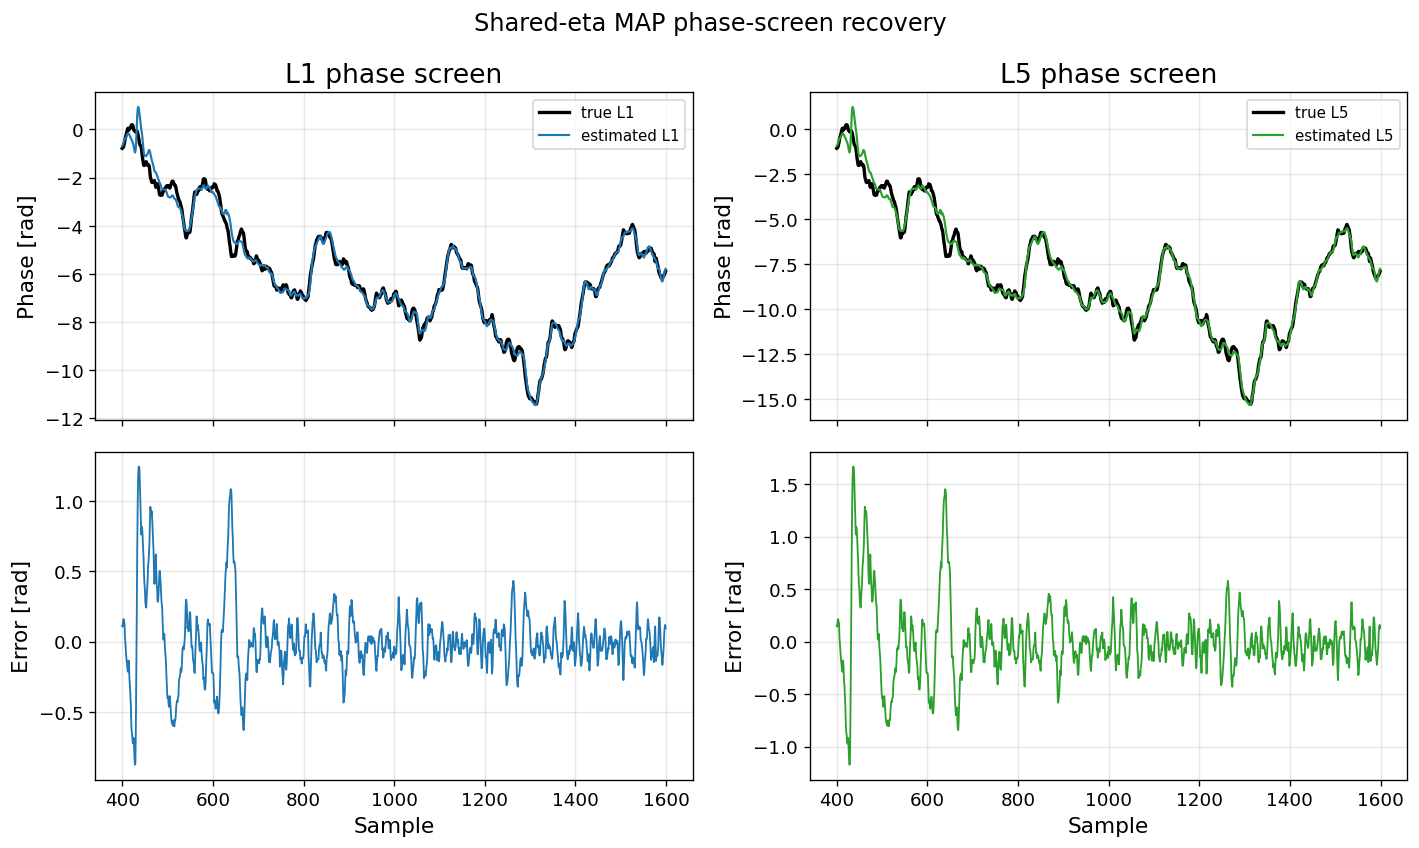

In [10]:
plot_start_eff = min(max(0, int(plot_start)), max(0, N - 1))
plot_stop = min(plot_start_eff + int(plot_len), N)
if plot_stop <= plot_start_eff:
    raise ValueError(f"Empty plot window for N={N}, plot_start={plot_start}, plot_len={plot_len}")
sl = slice(plot_start_eff, plot_stop)
samples = np.arange(work_start + plot_start_eff, work_start + plot_stop)

phi_l1_hat = unwrap_align(final_state["phi_l1"], true_phi_l1)
phi_l5_hat = unwrap_align(final_state["phi_l5"], true_phi_l5)
true_phi_l1_unwrapped = np.unwrap(true_phi_l1)
true_phi_l5_unwrapped = np.unwrap(true_phi_l5)

phase_plot_df = pd.DataFrame(
    {
        "sample": samples,
        "true_phi_l1_rad": true_phi_l1_unwrapped[sl],
        "hat_phi_l1_aligned_rad": phi_l1_hat[sl],
        "error_phi_l1_rad": phi_l1_hat[sl] - true_phi_l1_unwrapped[sl],
        "true_phi_l5_rad": true_phi_l5_unwrapped[sl],
        "hat_phi_l5_aligned_rad": phi_l5_hat[sl],
        "error_phi_l5_rad": phi_l5_hat[sl] - true_phi_l5_unwrapped[sl],
    }
)
phase_plot_df.to_csv(output_dir / "shared_eta_phase_example.csv", index=False)

phase_diagnostic_rows = []
phase_error_by_band = {
    "L1": phi_l1_hat - true_phi_l1_unwrapped,
    "L5": phi_l5_hat - true_phi_l5_unwrapped,
}
edge_guard = int(min(max(0, phase_edge_guard_samples), max(0, N // 2 - 1)))
regions = {"full": np.ones(N, dtype=bool)}
if edge_guard > 0:
    interior = np.zeros(N, dtype=bool)
    interior[edge_guard : N - edge_guard] = True
    regions[f"interior_guard_{edge_guard}"] = interior

full_phase_columns = {"sample": np.arange(work_start, work_stop)}
for band, err_raw in phase_error_by_band.items():
    err = err_raw - np.nanmedian(err_raw)
    wrapped_err = np.angle(np.exp(1j * err))
    branch_offset = np.round((err - wrapped_err) / (2.0 * np.pi)).astype(int)
    values, counts = np.unique(branch_offset, return_counts=True)
    for region_name, region_idx in regions.items():
        region_err = err[region_idx]
        region_wrapped = wrapped_err[region_idx]
        region_branch = branch_offset[region_idx]
        region_values, region_counts = np.unique(region_branch, return_counts=True)
        phase_diagnostic_rows.append(
            {
                "band": band,
                "region": region_name,
                "num_samples": int(np.sum(region_idx)),
                "rmse_rad": float(np.sqrt(np.mean(region_err ** 2))),
                "wrapped_rmse_rad": float(np.sqrt(np.mean(region_wrapped ** 2))),
                "max_abs_error_rad": float(np.max(np.abs(region_err))),
                "num_branch_offset_samples": int(np.sum(region_branch != 0)),
                "max_abs_branch_offset": int(np.max(np.abs(region_branch))) if len(region_branch) else 0,
                "branch_offset_counts": json.dumps({int(v): int(c) for v, c in zip(region_values, region_counts)}),
            }
        )
    key = band.lower()
    full_phase_columns[f"error_phi_{key}_rad"] = err_raw
    full_phase_columns[f"error_phi_{key}_median_aligned_rad"] = err
    full_phase_columns[f"wrapped_error_phi_{key}_rad"] = wrapped_err
    full_phase_columns[f"branch_offset_{key}"] = branch_offset

phase_diagnostics_df = pd.DataFrame(phase_diagnostic_rows)
phase_diagnostics_df.to_csv(output_dir / "shared_eta_phase_diagnostics.csv", index=False)
full_phase_df = pd.DataFrame(
    {
        **full_phase_columns,
        "true_phi_l1_rad": true_phi_l1_unwrapped,
        "hat_phi_l1_aligned_rad": phi_l1_hat,
        "true_phi_l5_rad": true_phi_l5_unwrapped,
        "hat_phi_l5_aligned_rad": phi_l5_hat,
    }
)
full_phase_df.to_csv(output_dir / "shared_eta_phase_full.csv", index=False)
logger.info("Full/interior phase diagnostics: \n{}", phase_diagnostics_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12.0, 7.2), sharex=True)
axes[0, 0].plot(samples, true_phi_l1_unwrapped[sl], "k", linewidth=2.0, label="true L1")
axes[0, 0].plot(samples, phi_l1_hat[sl], color="tab:blue", linewidth=1.3, label="estimated L1")
axes[1, 0].plot(samples, phi_l1_hat[sl] - true_phi_l1_unwrapped[sl], color="tab:blue", linewidth=1.1)
axes[0, 1].plot(samples, true_phi_l5_unwrapped[sl], "k", linewidth=2.0, label="true L5")
axes[0, 1].plot(samples, phi_l5_hat[sl], color="tab:green", linewidth=1.3, label="estimated L5")
axes[1, 1].plot(samples, phi_l5_hat[sl] - true_phi_l5_unwrapped[sl], color="tab:green", linewidth=1.1)

axes[0, 0].set_title("L1 phase screen")
axes[0, 1].set_title("L5 phase screen")
axes[1, 0].set_ylabel("Error [rad]")
axes[1, 1].set_ylabel("Error [rad]")
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
for ax in axes[0, :]:
    ax.set_ylabel("Phase [rad]")
    ax.legend()
for ax in axes[1, :]:
    ax.set_xlabel("Sample")
fig.suptitle("Shared-eta MAP phase-screen recovery")
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "shared_eta_phase_recovery_example.png", dpi=300)
plt.show()


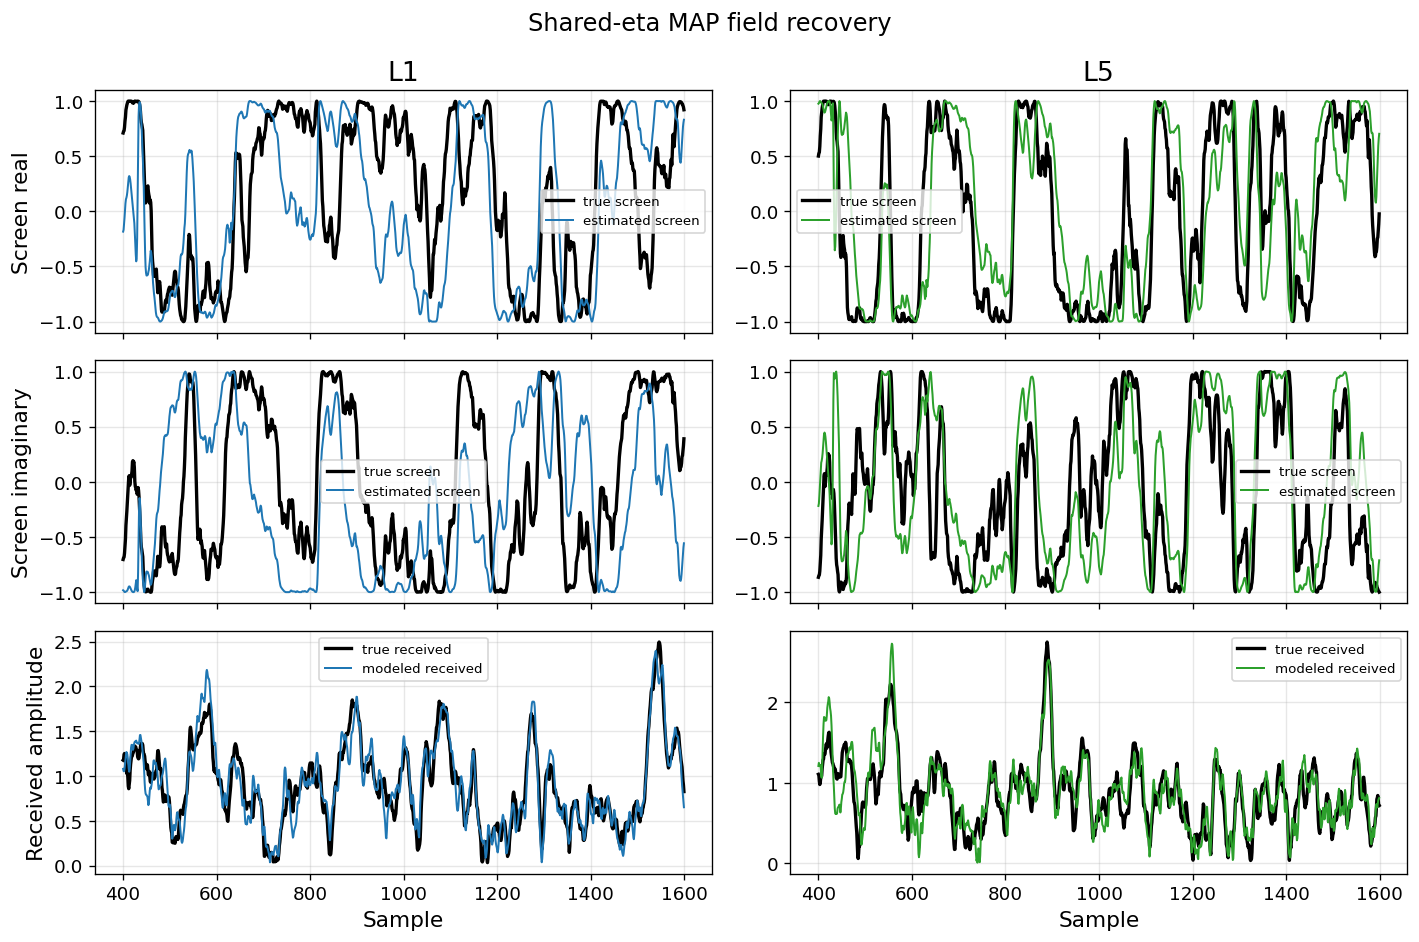

In [11]:
field_plot_df = pd.DataFrame(
    {
        "sample": samples,
        "true_screen_l1_real": np.real(true_screen_l1[sl]),
        "hat_screen_l1_real": np.real(final_state["screen_l1"][sl]),
        "true_screen_l1_imag": np.imag(true_screen_l1[sl]),
        "hat_screen_l1_imag": np.imag(final_state["screen_l1"][sl]),
        "true_rx_l1_abs": np.abs(y_l1[sl]),
        "hat_rx_l1_abs": np.abs(final_state["yhat_l1"][sl]),
        "true_screen_l5_real": np.real(true_screen_l5[sl]),
        "hat_screen_l5_real": np.real(final_state["screen_l5"][sl]),
        "true_screen_l5_imag": np.imag(true_screen_l5[sl]),
        "hat_screen_l5_imag": np.imag(final_state["screen_l5"][sl]),
        "true_rx_l5_abs": np.abs(y_l5[sl]),
        "hat_rx_l5_abs": np.abs(final_state["yhat_l5"][sl]),
    }
)
field_plot_df.to_csv(output_dir / "shared_eta_field_example.csv", index=False)

fig, axes = plt.subplots(3, 2, figsize=(12.0, 8.0), sharex=True)
for col, band, true_screen, hat_screen, y_true, y_hat, color in [
    (0, "L1", true_screen_l1, final_state["screen_l1"], y_l1, final_state["yhat_l1"], "tab:blue"),
    (1, "L5", true_screen_l5, final_state["screen_l5"], y_l5, final_state["yhat_l5"], "tab:green"),
]:
    axes[0, col].plot(samples, np.real(true_screen[sl]), "k", linewidth=2.0, label="true screen")
    axes[0, col].plot(samples, np.real(hat_screen[sl]), color=color, linewidth=1.2, label="estimated screen")
    axes[1, col].plot(samples, np.imag(true_screen[sl]), "k", linewidth=2.0, label="true screen")
    axes[1, col].plot(samples, np.imag(hat_screen[sl]), color=color, linewidth=1.2, label="estimated screen")
    axes[2, col].plot(samples, np.abs(y_true[sl]), "k", linewidth=2.0, label="true received")
    axes[2, col].plot(samples, np.abs(y_hat[sl]), color=color, linewidth=1.2, label="modeled received")
    axes[0, col].set_title(band)
    axes[2, col].set_xlabel("Sample")

axes[0, 0].set_ylabel("Screen real")
axes[1, 0].set_ylabel("Screen imaginary")
axes[2, 0].set_ylabel("Received amplitude")
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Shared-eta MAP field recovery")
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "shared_eta_field_recovery_example.png", dpi=300)
plt.show()


## Notes

- The notebook uses staged spectral continuation: low-frequency eta modes are optimized first with stronger phase-gradient regularization, then more modes are unlocked. Each stage uses `scipy.optimize.least_squares` with the large-scale trust-region reflective solver and an analytic `LinearOperator` Jacobian.
- Dense Levenberg-Marquardt is not practical for the full `N=15000` problem because it would require a very large dense Jacobian. The default `N_WORK=2048` keeps the first test much safer.
- The `true_l1_phase_sanity` initialization is included only to check implementation consistency. It should not be used as an operational estimator.
- Saving the true simulator `eta` in a future dataset would be useful for debugging and identifiability studies, but it is not required for the screen/field recovery experiment implemented here.
